# Live: DDS transmit and FPGA spectrum, over the air

The signal chain of this notebook has no software in it: the **DDS** generates a tone (frequency and amplitude from registers), it is transmitted by TX1, received by RX1,
and the **FFT chain** computes the spectrum in the FPGA. Python only starts the DMA, reads the power values and draws them: a live spectrum, max hold and a waterfall,
with sliders for frequency and amplitude, a sweep, and a transmit switch.

**Before you start:** the overlay of `P501_DDS_FFT_Tutorial.ipynb` (folder `p501_fft_dds`); TX1 and RX1 antennas near each other or a cable with at least 40 dB attenuation:
never connect them directly. **The tone stays on until you turn it off**, also if you close the tab or a cell fails: run the last cell (*Stop and silence*) when you are done.

1. Run the cells down to *Self-test*. 2. Run *Controls* and press **Start**. 3. **Stop**, then *Stop and silence*.

## Configuration, overlay and bring-up

In [1]:
BIT         = "/home/xilinx/jupyter_notebooks/p501_fft_dds/p501_fft_dds.bit"   # overlay with the DDS and the FFT (the .hwh next to it)
NFFT_LOG2   = 10                 # FFT length 2^10 = 1024: must equal the value the overlay was built with
FS          = 3_840_000          # sample rate (3.84 MSPS)
LO          = 700_000_000        # RF centre frequency, Hz
RF_BW       = 4_000_000          # analog bandwidth, Hz
TX_ATTEN    = 10                 # dB
RX_GAIN     = 45                 # gain-table index 0..76
SETTLE_BIN  = 267                # test tone of the bring-up: exactly on this FFT bin

In [2]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt
from pynq import Overlay

sys.path.insert(0, '/home/xilinx/jupyter_notebooks')
sys.path.insert(0, '/home/xilinx/jupyter_notebooks/p501_fft_dds')       # p501_radio.py, p501_dds.py, p501_fft.py
import p501_radio
from p501_dds import P501Dds
from p501_fft import P501Fft

results = {}
def check(name, ok, detail):
    results[name] = (bool(ok), detail)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: {detail}")

ol  = Overlay(BIT)                                   # programs the PL: DDS + FFT chain + the base design
dds = P501Dds(ol.dds_regs, FS)                       # tone generator  (registers at 0x9C450000)
fft = P501Fft(ol.fft_dma, NFFT_LOG2, FS)             # spectrum reader (DMA at 0x9C440000)

def tone(freq_hz=None, amp=None, enable=None, wait_s=0.003):
    """dds.set(...), then wait: the radio chain and the FFT pipeline still hold about two frames (0.5 ms) of the old signal."""
    dds.set(freq_hz=freq_hz, amp=amp, enable=enable)
    time.sleep(wait_s)

a_fft, a_dds = ol.ip_dict["fft_dma"]["phys_addr"], ol.ip_dict["dds_regs"]["phys_addr"]
check("both blocks in the overlay", a_fft == 0x9C440000 and a_dds == 0x9C450000, f"fft_dma at 0x{a_fft:08X}, dds_regs at 0x{a_dds:08X}")

PASS  both blocks in the overlay: fft_dma at 0x9C440000, dds_regs at 0x9C450000


In [3]:
F_SETTLE = SETTLE_BIN * fft.bin_hz                   # a tone exactly on an FFT bin: no leakage into the neighbours

def measure():
    """Image rejection of the test tone, from the FFT frames computed in the FPGA."""
    tone(freq_hz=F_SETTLE, amp=0.5)
    return fft.image_rejection_db(fft.average(8), F_SETTLE)

ad = p501_radio.bring_up(ol, LO, RF_BW, TX_ATTEN, RX_GAIN)       # the AD9361 is configured over SPI: one call
rej, tries = p501_radio.settle(ad, ol, measure)                  # repeat until the tone is clean (known AD9361 analog-state issue)
print(f"settled after {tries} tries, image rejection {rej:.1f} dB")
check("AD9361 up", ad.info["ok"], f"LO locks {ad.info['rx_lock']}/{ad.info['tx_lock']}, ENSM 0x{ad.info['ensm']:X}, calibrations {ad.info['calibrations']}")

settled after 5 tries, image rejection 50.2 dB
PASS  AD9361 up: LO locks True/True, ENSM 0xA, calibrations {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}


## The live machinery

* `fft.average(n)` reads *n* spectra computed by the FPGA: this replaces both the raw ADC capture and the NumPy FFT of the DDS-only live notebook.
* `render()` draws the spectrum as a polyline, a max-hold trace and a waterfall with NumPy and Pillow (matplotlib needs about 0.4 s per figure on the Zynq's ARM cores).
* `Live` runs `read -> picture` in a background thread and puts the PNG into an image widget, so the sliders stay responsive.

In [4]:
import threading, io
import ipywidgets as widgets
from IPython.display import display, Image as IPImage
from PIL import Image as PILImage, ImageDraw, ImageFont
from matplotlib import cm

NB, HIST, NFR = fft.n, 60, 4                          # bins shown, waterfall depth, frames averaged per picture
f_disp = fft.freqs / 1e3                              # kHz

W, H = 800, 560
L, R, T = 56, 14, 30
SP_H, WF_H, GAP = 250, 180, 44
SP_Y0, WF_Y0 = T, T + SP_H + GAP
PW = W - L - R
YMIN, YMAX = -5.0, 85.0                               # spectrum dB range
WMIN, WMAX = 0.0, 75.0                                # waterfall colour range
EDGES = np.linspace(0, NB, PW + 1).astype(int)[:-1]
LUT = (cm.get_cmap("viridis")(np.linspace(0, 1, 256))[:, :3] * 255).astype(np.uint8)
FONT = ImageFont.load_default()
hist = np.full((HIST, NB), np.nan)
maxhold = np.full(NB, -50.0)

def x_of(f_khz):
    return L + (f_khz - f_disp[0]) / (f_disp[-1] - f_disp[0]) * (PW - 1)

def y_of(db):
    return SP_Y0 + SP_H - (np.clip(db, YMIN, YMAX) - YMIN) / (YMAX - YMIN) * SP_H

def frame_base():
    img = PILImage.new("RGB", (W, H), (255, 255, 255)); d = ImageDraw.Draw(img)
    d.rectangle([L, SP_Y0, L + PW, SP_Y0 + SP_H], outline=(90, 90, 90)); d.rectangle([L, WF_Y0, L + PW, WF_Y0 + WF_H], outline=(90, 90, 90))
    for db in range(0, 86, 10):
        y = int(y_of(db)); d.line([L, y, L + PW, y], fill=(225, 225, 225)); d.text((L - 30, y - 5), f"{db}", fill=(60, 60, 60), font=FONT)
    for fk in range(-1500, 1501, 500):
        x = int(x_of(fk)); d.line([x, SP_Y0, x, SP_Y0 + SP_H], fill=(225, 225, 225)); d.text((x - 14, WF_Y0 + WF_H + 4), f"{fk}", fill=(60, 60, 60), font=FONT)
    d.text((L + PW // 2 - 40, WF_Y0 + WF_H + 18), "kHz from the LO", fill=(60, 60, 60), font=FONT)
    d.text((6, SP_Y0 + SP_H // 2 - 5), "dB", fill=(60, 60, 60), font=FONT); d.text((6, WF_Y0 + WF_H // 2 - 5), "time", fill=(60, 60, 60), font=FONT)
    return img

BASE = frame_base()

def render(avg, f_set, rate=None):
    """Draw one averaged spectrum (power, fftshifted) and return the picture as PNG bytes."""
    global maxhold
    disp = fft.db(avg)
    hist[:-1] = hist[1:]; hist[-1] = disp
    maxhold = np.fmax(maxhold, disp)
    img = BASE.copy(); d = ImageDraw.Draw(img)
    xs = L + np.arange(PW)
    d.line(list(zip(xs, y_of(np.maximum.reduceat(maxhold, EDGES)))), fill=(170, 170, 170), width=1)
    d.line(list(zip(xs, y_of(np.maximum.reduceat(disp, EDGES)))), fill=(31, 119, 180), width=1)
    xm = int(x_of(f_set / 1e3))
    for y in range(SP_Y0, SP_Y0 + SP_H, 8):
        d.line([xm, y, xm, y + 4], fill=(44, 160, 44))
    wf = np.maximum.reduceat(np.nan_to_num(hist, nan=-100.0), EDGES, axis=1)
    idx = np.clip((wf - WMIN) / (WMAX - WMIN) * 255, 0, 255).astype(np.uint8)
    img.paste(PILImage.fromarray(LUT[idx]).resize((PW, WF_H), PILImage.NEAREST), (L + 1, WF_Y0 + 1))
    f_pk, l_pk = fft.peak(avg)
    d.text((L, 8), f"set {f_set/1e3:+.1f} kHz    FFT peak {f_pk/1e3:+.2f} kHz    {l_pk:.0f} dB" + (f"    {rate:.1f} pictures/s" if rate else ""), fill=(0, 0, 0), font=FONT)
    buf = io.BytesIO(); img.save(buf, format="PNG", compress_level=1)
    return buf.getvalue()

def reset_traces():
    global maxhold
    maxhold = np.full(NB, -50.0); hist[:] = np.nan

class Live:
    """Background thread: read spectra from the FPGA, draw; sweeps the DDS frequency when the sweep box is ticked."""
    def __init__(self, image, status, ui):
        self.image, self.status, self.ui = image, status, ui
        self.running, self.thread, self.frames = False, None, 0
    def _run(self):
        t_start = t_rate = time.time(); n_rate = 0; rate = None
        while self.running:
            if self.ui["sweep"].value:                                # sawtooth sweep over -1.5 .. +1.5 MHz in ~6 s
                f = -1.5e6 + ((time.time() - t_start) % 6.0) / 6.0 * 3.0e6
                dds.set(freq_hz=f)
            else:
                f = dds.freq_hz
            self.image.value = render(fft.average(NFR), f, rate)
            self.frames += 1; n_rate += 1
            if time.time() - t_rate > 2:
                rate = n_rate / (time.time() - t_rate); t_rate = time.time(); n_rate = 0
        self.status.value = f"stopped after {self.frames} pictures"
    def start(self):
        if self.thread is None or not self.thread.is_alive():
            self.running = True; self.frames = 0
            self.thread = threading.Thread(target=self._run, daemon=True); self.thread.start()
            self.status.value = "running"
    def stop(self):
        self.running = False
        if self.thread is not None:
            self.thread.join(timeout=5)

## Self-test

A few pictures without a browser: checks the chain DDS -> air -> FFT -> picture, the speed, and the background thread with the sweep on.

PASS  live pictures: 10.0 pictures/s, FFT peak at 499.38 kHz, 63 dB


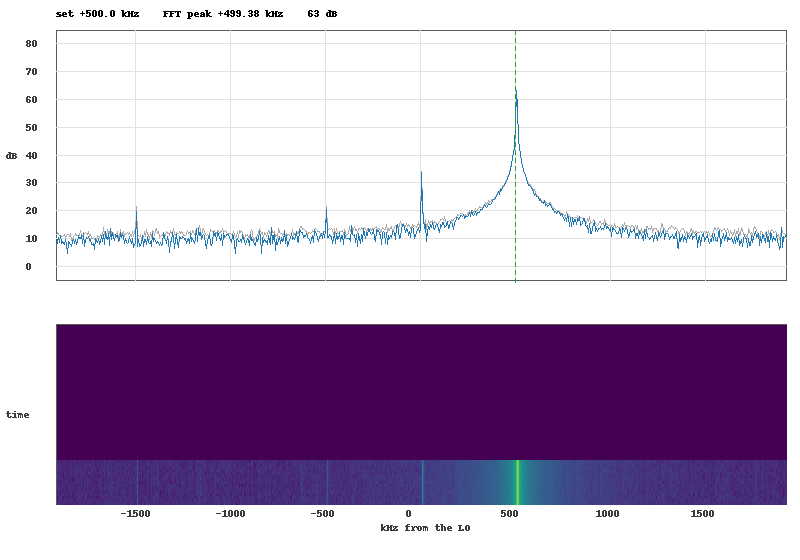

PASS  live thread with sweep: 28 pictures in 3 s, the thread moved the DDS (now -52 kHz)


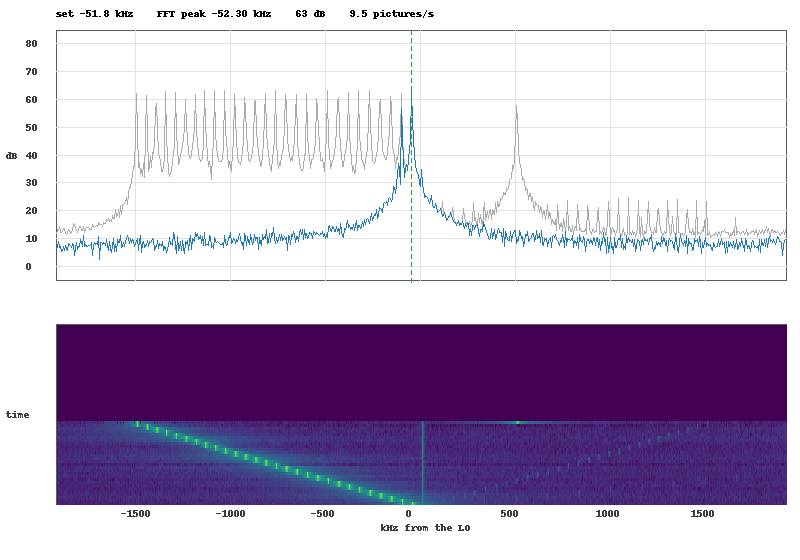

In [5]:
dds.set(freq_hz=500e3, amp=0.5)
reset_traces()
n = 15; t0 = time.time()
for i in range(n):
    avg = fft.average(NFR); png = render(avg, 500e3)
fps = n / (time.time() - t0)
f_pk, l_pk = fft.peak(avg)
check("live pictures", abs(f_pk - 500e3) < fft.bin_hz and fps > 5, f"{fps:.1f} pictures/s, FFT peak at {f_pk/1e3:.2f} kHz, {l_pk:.0f} dB")
display(IPImage(png))

sweep_box, img_w, st = widgets.Checkbox(value=True), widgets.Image(format="png"), widgets.Label()
lv = Live(img_w, st, {"sweep": sweep_box}); reset_traces()
lv.start(); time.sleep(3); lv.stop()
check("live thread with sweep", lv.frames > 10 and len(img_w.value) > 1000, f"{lv.frames} pictures in 3 s, the thread moved the DDS (now {dds.freq_hz/1e3:+.0f} kHz)")
display(IPImage(img_w.value))

## Controls

* **Transmit**: the DDS enable. **Frequency / Amplitude**: written to the DDS registers as you move the slider. **Sweep**: -1.5 to +1.5 MHz in 6 s, repeated.
* **Digital loopback**: the chip feeds its TX data to its own RX data port: the same chain without the antennas.
* **Start / Stop**: the live display. Stopping the display does *not* stop the tone.

In [6]:
w_tx   = widgets.Checkbox(value=True, description="Transmit")
w_freq = widgets.FloatSlider(value=500, min=-1800, max=1800, step=10, description="Freq (kHz)", continuous_update=True, layout=widgets.Layout(width="520px"))
w_amp  = widgets.FloatSlider(value=0.5, min=0, max=1, step=0.01, description="Amplitude", continuous_update=True, layout=widgets.Layout(width="520px"))
w_swp  = widgets.Checkbox(value=False, description="Sweep")
w_loop = widgets.Checkbox(value=False, description="Digital loopback")
b_start, b_stop = widgets.Button(description="Start", button_style="success"), widgets.Button(description="Stop", button_style="warning")
status = widgets.Label(value="idle")
image  = widgets.Image(format="png", width=720)
live = Live(image, status, {"sweep": w_swp})

def guard(fn):
    def h(change=None):
        try:
            fn(change)
        except Exception as e:
            status.value = f"{type(e).__name__}: {e}"
    return h

w_freq.observe(guard(lambda c: (not w_swp.value) and dds.set(freq_hz=c["new"] * 1e3)), names="value")
w_amp.observe(guard(lambda c: dds.set(amp=c["new"])), names="value")
w_tx.observe(guard(lambda c: dds.set(enable=c["new"])), names="value")
w_loop.observe(guard(lambda c: p501_radio.loopback(ad, c["new"])), names="value")
b_start.on_click(guard(lambda b: (dds.set(freq_hz=w_freq.value * 1e3, amp=w_amp.value, enable=w_tx.value), reset_traces(), live.start())))
b_stop.on_click(guard(lambda b: live.stop()))

dds.set(freq_hz=w_freq.value * 1e3, amp=w_amp.value, enable=w_tx.value)
display(widgets.VBox([widgets.HBox([b_start, b_stop, status]), widgets.HBox([w_tx, w_swp, w_loop]), w_freq, w_amp, image]))

### Check the controls (optional)

Moves every control from Python, the way a click would, and checks that the DDS and the display follow.

PASS  slider: frequency: DDS at 300.000 kHz
PASS  slider: amplitude: DDS amplitude 0.250
PASS  checkbox: transmit off: enabled = False
PASS  checkbox: transmit on: enabled = True
PASS  checkbox: digital loopback: 0x01
PASS  buttons: start / stop: 27 pictures, status: stopped after 27 pictures


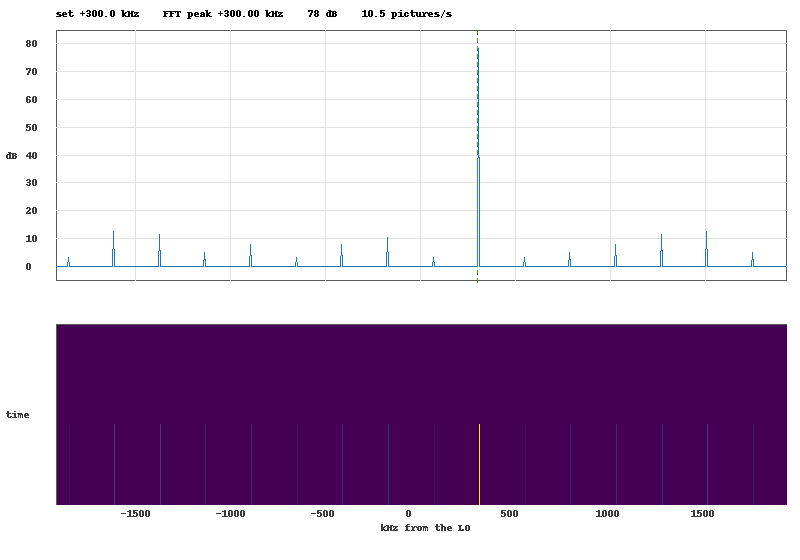

In [7]:
w_freq.value = 300;  check("slider: frequency", abs(dds.freq_hz - 300e3) < 1, f"DDS at {dds.freq_hz/1e3:.3f} kHz")
w_amp.value = 0.25;  check("slider: amplitude", abs(dds.amp - 0.25) < 0.001, f"DDS amplitude {dds.amp:.3f}")
w_tx.value = False;  check("checkbox: transmit off", not dds.enabled, f"enabled = {dds.enabled}")
w_tx.value = True;   check("checkbox: transmit on", dds.enabled, f"enabled = {dds.enabled}")
w_loop.value = True; check("checkbox: digital loopback", ad.reg_read(p501_radio.OBS) & 1, f"0x{ad.reg_read(p501_radio.OBS):02X}")
b_start.click(); time.sleep(2.5); b_stop.click()
check("buttons: start / stop", live.frames > 5 and not live.running and len(image.value) > 1000, f"{live.frames} pictures, status: {status.value}")
w_loop.value = False
display(IPImage(image.value))

## Stop and silence

Run this when you are done (or after an error): stops the display, turns the DDS off and the digital loopback off, and sets a high TX attenuation. The AD9361
transmit chain stays powered (a weak LO carrier remains); loading another overlay or powering down gives complete silence.

In [8]:
try:
    live.stop()
finally:
    dds.off()
    p501_radio.loopback(ad, False)
    p501_radio.quiet(ad, 80)
    print("DDS off, loopback off, TX attenuation 80 dB")

DDS off, loopback off, TX attenuation 80 dB
